# Choosing the best solver

Cassiopeia offers several solvers for reconstructing trees from character matrices. Which one works best
depends on the lineage tracing technology and on the quality of the data. In this tutorial we use
simulations to compare the solvers for four technologies, with up to 50% missing data and up to 5% of
miscalled sites, and measure how long each takes.

| Solver | Approach |
|---|---|
| {func}`cassiopeia.solver.nj` | Neighbor joining: repeatedly joins the closest pair of cells or clades. |
| {func}`cassiopeia.solver.upgma` | Hierarchical clustering with average linkage. Assumes edits accumulate at the same rate in every lineage. |
| {func}`cassiopeia.solver.greedy` | Top-down: splits cells on the most frequent edit, weighted by its rarity ([Jones et al. 2020](https://doi.org/10.1186/s13059-020-02000-8)). |
| {func}`cassiopeia.solver.ilp` | Finds a maximum parsimony tree with integer linear programming. |
| {func}`cassiopeia.solver.hybrid` | Greedy splits at the top of the tree, then another solver (by default ILP) for each small subproblem. |

The ILP solver scales to only a few hundred cells, so we use it as the bottom solver of `hybrid`
(Cassiopeia-Hybrid in [Jones et al. 2020](https://doi.org/10.1186/s13059-020-02000-8)). It requires
[Gurobi](https://www.gurobi.com): `pip install gurobipy` and a license, which is free for academic
use. To learn how to build a benchmark step by step, see the
[benchmarking pipeline](benchmark.ipynb).

In [1]:
import time
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pycea as py
import seaborn as sns
from joblib import Parallel, delayed

import cassiopeia as cas

## Tracing technologies

{func}`cassiopeia.sim.stochastic_tracing` simulates the edits of many lineage tracing technologies. We
compare four, which differ in how many outcomes each site has, how likely each outcome is, and whether
sites are edited independently:

* **Cas9 indels**, e.g. KP-tracer ([Yang et al. 2022](https://doi.org/10.1016/j.cell.2022.04.015)):
  10 cassettes of 3 sites, edited independently, with 100 possible indels of very different
  frequencies.
* **Prime editing**, e.g. PEtracer ([Koblan et al. 2025](https://doi.org/10.1101/2025.06.15.659774)):
  10 cassettes of 3 sites, with 8 equally likely insertions.
* **DNA Typewriter** ([Choi et al. 2022](https://doi.org/10.1038/s41586-022-04922-8)): 6 tapes of 5
  sites that are edited in order, with 16 equally likely insertions.
* **Base editing**: 60 sites with a single possible edit each.

Times are scaled from 0 to 1, and editing rates are set so that about 60% of the sites are edited by
the end.

In [2]:
TECHNOLOGIES = {
    "Cas9 indels": {"number_of_cassettes": 10, "size_of_cassette": 3, "number_of_states": 100},
    "Prime editing": {
        "number_of_cassettes": 10,
        "size_of_cassette": 3,
        "state_priors": {str(i): 1 / 8 for i in range(1, 9)},
    },
    "DNA Typewriter": {
        "number_of_cassettes": 6,
        "size_of_cassette": 5,
        "initiation_rate": 3.0,
        "continuation_rate": 3.0,
        "state_priors": {str(i): 1 / 16 for i in range(1, 17)},
    },
    "Base editing": {"number_of_cassettes": 60, "size_of_cassette": 1, "state_priors": {"1": 1.0}},
}


def simulate(technology, missing=0.0, noise=0.0, random_seed=0, n_cells=1000):
    """Simulate a tree with lineage tracing data, missing data and noise."""
    tdata = cas.sim.birth_death_process(num_extant=n_cells, random_seed=random_seed)
    cas.tl.rescale_node_times(tdata)
    cas.sim.stochastic_tracing(
        tdata, mutation_rate=1.0, random_seed=random_seed, **TECHNOLOGIES[technology]
    )
    if missing:
        cas.sim.missing_data(tdata, stochastic_rate=missing, random_seed=random_seed)
    if noise:
        cas.sim.noise(tdata, error_rate=noise, priors=True, random_seed=random_seed)
    return tdata

Here is what the data look like for 200 cells, plotted with [pycea](https://pycea.readthedocs.io/en/latest/):

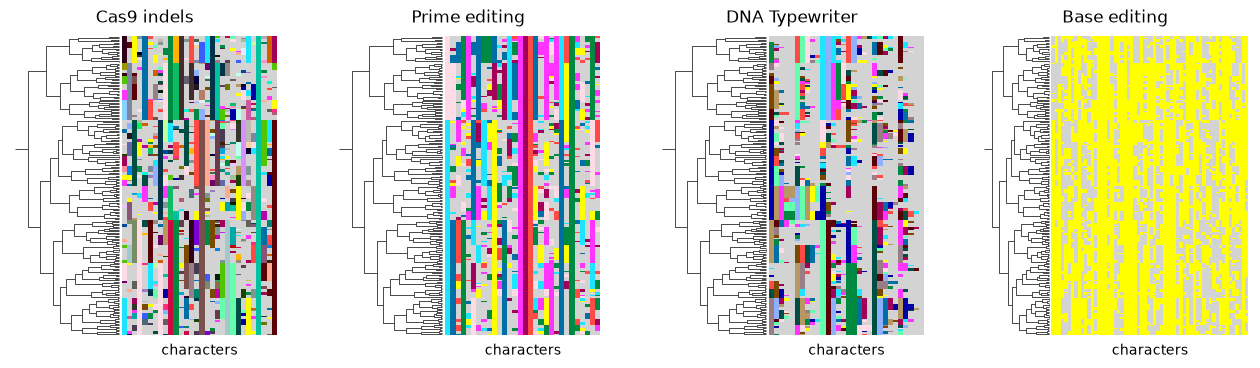

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, technology in zip(axes, TECHNOLOGIES, strict=True):
    tdata = simulate(technology, n_cells=200)
    py.pl.tree(tdata, depth_key="time", keys="characters", legend=False, ax=ax)
    ax.set_title(technology)

## The benchmark

Each solver adds a tree to `tdata.obst`, under the solver's name. Greedy and hybrid weight edits by their
priors, which `stochastic_tracing` stores in `tdata.uns["priors"]` (`priors=True`). Hybrid splits the
cells with greedy until at most 30 remain (`cell_cutoff`) and solves each of these subproblems with
the ILP. The ILP gets slow on larger subproblems with missing data, so to keep the benchmark
manageable we use small subproblems and stop the ILP after 10 seconds per subproblem
(`convergence_time_limit`), keeping its best tree so far. The other solvers use their default
settings. Without a Gurobi license, remove `hybrid` from `SOLVERS` or give it another bottom solver
(e.g. `bottom_solver="nj"`).

In [4]:
SOLVERS = {
    "nj": cas.solver.nj,
    "upgma": cas.solver.upgma,
    "greedy": partial(cas.solver.greedy, priors=True),
    "hybrid": partial(
        cas.solver.hybrid,
        cell_cutoff=30,
        bottom_kwargs={"convergence_time_limit": 10},
        priors=True,
        progress_bar=False,
    ),
}

We compare each reconstruction with the simulated tree using two metrics from `cas.critique`:

* {func}`cassiopeia.critique.robinson_foulds`: the fraction of clades that differ between the trees
  (normalized RF distance, lower is better).
* {func}`cassiopeia.critique.triplets_correct`: the fraction of sampled triplets of cells that the
  reconstruction groups correctly, averaged over the depth of their common ancestor (higher is better).

In [5]:
def evaluate(tdata, key):
    """Compare the tree in `obst[key]` with the simulated tree."""
    rf, max_rf = cas.critique.robinson_foulds(tdata, key1="simulated", key2=key)
    triplets, _, _, _ = cas.critique.triplets_correct(
        tdata, key1="simulated", key2=key, number_of_trials=200
    )
    return {"rf": rf / max_rf, "triplets": np.mean(list(triplets.values()))}


def benchmark(technology, missing, noise, random_seed):
    """Simulate data, reconstruct it with every solver and evaluate the trees."""
    tdata = simulate(technology, missing, noise, random_seed)
    results = []
    for solver, reconstruct in SOLVERS.items():
        start = time.time()
        reconstruct(tdata)
        seconds = time.time() - start
        conditions = {"technology": technology, "missing": missing, "noise": noise}
        metrics = evaluate(tdata, solver)
        results.append({**conditions, "solver": solver, **metrics, "seconds": seconds})
    return results

We simulate 1,000 cells for every combination of technology, missing data (0, 10, 25 and 50% of the
sites) and noise (0, 1 and 5% of the sites miscalled), with 5 replicates each. The 240 simulations run
in parallel with [joblib](https://joblib.readthedocs.io). This takes about an hour on 24 cores, almost
all of it spent in the ILP subproblems of hybrid; without hybrid it takes a few minutes.

In [6]:
runs = [
    (technology, missing, noise, seed)
    for technology in TECHNOLOGIES
    for missing in [0, 0.1, 0.25, 0.5]
    for noise in [0, 0.01, 0.05]
    for seed in range(5)
]
results = Parallel(n_jobs=-1)(delayed(benchmark)(*run) for run in runs)
results = pd.DataFrame([row for rows in results for row in rows])
results.head()

,technology,missing,noise,solver,rf,triplets,seconds
0,Cas9 indels,0.0,0.0,nj,0.172518,0.890000,7.878330
1,Cas9 indels,0.0,0.0,upgma,0.245737,0.903462,3.011355
2,Cas9 indels,0.0,0.0,greedy,0.156297,0.928077,0.667709
3,Cas9 indels,0.0,0.0,hybrid,0.174675,0.892308,6.997472
4,Cas9 indels,0.0,0.0,nj,0.266800,0.831538,11.527420


## Accuracy

Each panel shows the RF distance as missing data increases, for one technology (columns) and noise
level (rows):

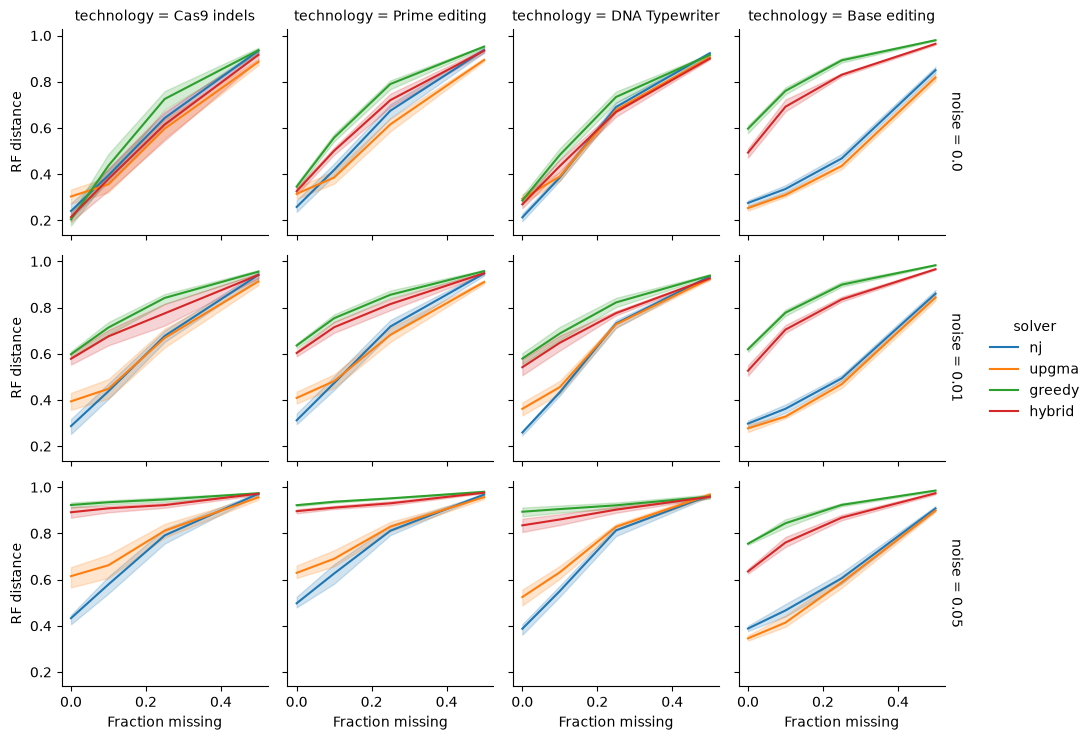

In [7]:
grid = {"row": "noise", "col": "technology", "hue": "solver", "kind": "line", "height": 2.5}
g = sns.relplot(results, x="missing", y="rf", facet_kws={"margin_titles": True}, **grid)
g.set_axis_labels("Fraction missing", "RF distance");

The same comparison with the triplets correct metric:

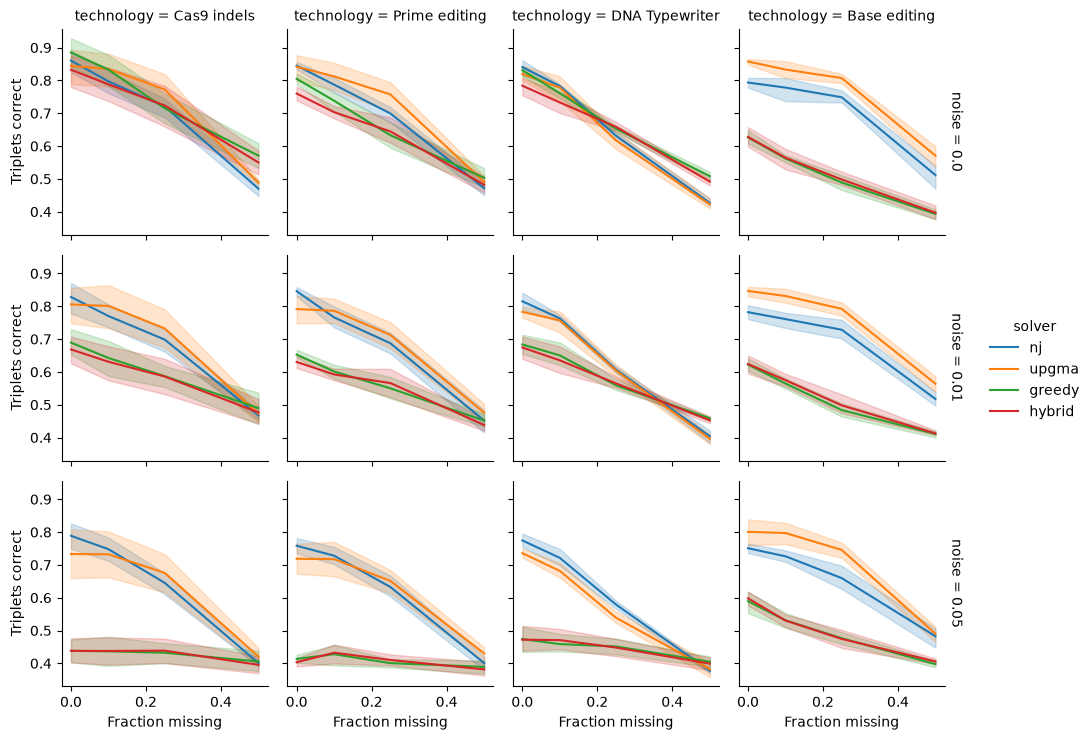

In [8]:
g = sns.relplot(results, x="missing", y="triplets", facet_kws={"margin_titles": True}, **grid)
g.set_axis_labels("Fraction missing", "Triplets correct");

The solver with the lowest mean RF distance for each condition:

In [9]:
mean_rf = results.groupby(["technology", "noise", "missing", "solver"])["rf"].mean()
mean_rf.unstack("solver").idxmin(axis=1).unstack("missing")

missing                 0.00   0.10    0.25    0.50
technology     noise                               
Base editing   0.00    upgma  upgma   upgma   upgma
               0.01    upgma  upgma   upgma   upgma
               0.05    upgma  upgma   upgma   upgma
Cas9 indels    0.00   greedy  upgma   upgma   upgma
               0.01       nj     nj   upgma   upgma
               0.05       nj     nj      nj   upgma
DNA Typewriter 0.00       nj     nj  hybrid  hybrid
               0.01       nj     nj   upgma   upgma
               0.05       nj     nj      nj  hybrid
Prime editing  0.00       nj  upgma   upgma   upgma
               0.01       nj     nj   upgma   upgma
               0.05       nj     nj      nj   upgma

A few patterns stand out:

* **Neighbor joining is the best choice in most conditions**, and the most robust to noise. With up to
  10% missing data it is the best solver in most conditions for Cas9 indels, prime editing and DNA
  Typewriter, and with 5% of the sites miscalled it stays well ahead of greedy and hybrid.
* **UPGMA is close to neighbor joining**. It is the best solver for base editing, where each site has a
  single outcome, and often when 25% or more of the sites are missing. It assumes that edits
  accumulate at the same rate in every lineage, which holds in these simulations.
* **Greedy does well for Cas9 indels without noise**, where the many rare indels make shared edits
  reliable markers of clades: it is the best solver with complete data.
* **Hybrid is slightly more accurate than greedy** in almost every condition, since the ILP improves
  the bottom of the tree, and it is the best solver for DNA Typewriter with many missing sites and no
  noise. Its top splits are greedy, though, so like greedy it degrades quickly once some sites are
  miscalled: a single miscalled edit can split a clade near the root. It also does poorly for base
  editing, where a single edit per site is a weak marker of a clade.
* With 50% missing data, all solvers struggle (RF distances above 0.8), and the differences between
  them are small.

For real data, which always contains some miscalled sites, we recommend starting with neighbor joining.

## Runtime

The mean runtime per reconstruction of 1,000 cells in the benchmark above (with all cores busy):

In [10]:
results.groupby(["solver"])["seconds"].mean().round(2)

solver
greedy      0.50
hybrid    268.94
nj          3.76
upgma       2.72
Name: seconds, dtype: float64

To see how the solvers scale, we reconstruct trees of up to 16,000 cells (Cas9 indels, 10% missing data).
This takes a few minutes.

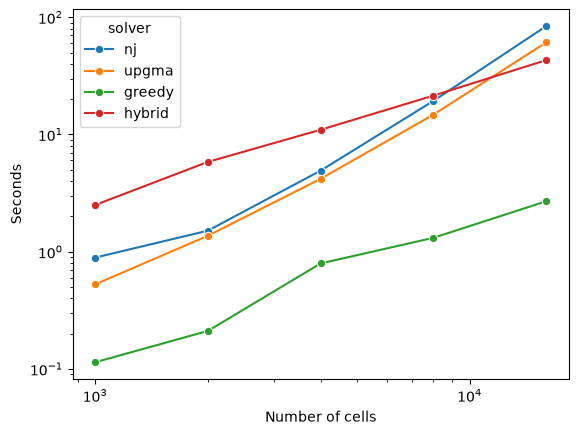

In [11]:
small = simulate("Cas9 indels", n_cells=100)
for reconstruct in SOLVERS.values():  # compile the numba kernels before timing
    reconstruct(small)

timings = []
for n_cells in [1000, 2000, 4000, 8000, 16000]:
    tdata = simulate("Cas9 indels", missing=0.1, n_cells=n_cells)
    for solver, reconstruct in SOLVERS.items():
        start = time.time()
        reconstruct(tdata)
        timings.append({"cells": n_cells, "solver": solver, "seconds": time.time() - start})
timings = pd.DataFrame(timings)

ax = sns.lineplot(timings, x="cells", y="seconds", hue="solver", marker="o")
ax.set(xscale="log", yscale="log", xlabel="Number of cells", ylabel="Seconds");

Greedy is by far the fastest. Neighbor joining and UPGMA compute all pairwise dissimilarities, so their
runtime grows faster with the number of cells, but they still reconstruct 16,000 cells in about a
minute. Hybrid is the slowest for small trees but grows more slowly, since the ILP only solves
subproblems of up to 30 cells. With 10% missing data these are solved quickly; with more missing data
or noise each subproblem can take up to the 10-second limit, which is why hybrid took minutes per tree
in the benchmark above. Distance computations can use several cores with the `threads` argument of
{func}`cassiopeia.solver.nj` and {func}`cassiopeia.solver.upgma`, and hybrid can solve subproblems in
parallel with its `threads` argument.

## Other options

Each solver has options that can improve its accuracy for a given dataset:

* The dissimilarity used by `nj` and `upgma` (`dissim_fn`), for example
  {func}`cassiopeia.dissimilarity.weighted_hamming` to weight edits by their priors.
* The rooting method of `nj` (`root`), see {func}`cassiopeia.solver.reroot`.
* The bottom solver and the cutoff of `hybrid` (`bottom_solver`, `cell_cutoff` or `lca_cutoff`), and
  the time limit of the ILP (`bottom_kwargs={"convergence_time_limit": ...}`).

These can be compared with the same approach on simulations that match your experiment. After
reconstruction, see the [basic tree reconstruction](reconstruct.ipynb) and
[branch length estimation](branch_lengths.ipynb) tutorials for the next steps.